<a href="https://colab.research.google.com/github/Cliveee-01/AQI_Mini-Project/blob/main/MINI_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rohanrao/air-quality-data-in-india")

print("Path to dataset files:", path)

100%|██████████| 72.9M/72.9M [00:00<00:00, 140MB/s]


Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/rohanrao/air-quality-data-in-india/versions/12


In [5]:
uploaded = files.upload()

csv_file = next(
    (name for name in uploaded if name.lower().endswith(".csv")),
    None
)

if csv_file is None:
    raise ValueError("Please upload a CSV file.")

df = pd.read_csv(csv_file)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Saving city_day.csv to city_day.csv
Dataset loaded successfully!
Dataset shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [2]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five rows:")
display(df.head())

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values in each column:")
display(df.isnull().sum().sort_values(ascending=False))

Number of rows and columns: (29531, 16)

Column names:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 no

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
City,29531,26,Ahmedabad,2009,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,29531,2009,2020-06-26,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PM2.5,24933.0,NaN,NaN,NaN,67.450578,64.661449,0.04,28.82,48.57,80.59,949.99
PM10,18391.0,NaN,NaN,NaN,118.127103,90.60511,0.01,56.255,95.68,149.745,1000.0
NO,25949.0,NaN,NaN,NaN,17.57473,22.785846,0.02,5.63,9.89,19.95,390.68
NO2,25946.0,NaN,NaN,NaN,28.560659,24.474746,0.01,11.75,21.69,37.62,362.21
NOx,25346.0,NaN,NaN,NaN,32.309123,31.646011,0.0,12.82,23.52,40.1275,467.63
NH3,19203.0,NaN,NaN,NaN,23.483476,25.684275,0.01,8.58,15.85,30.02,352.89
CO,27472.0,NaN,NaN,NaN,2.248598,6.962884,0.0,0.51,0.89,1.45,175.81
SO2,25677.0,NaN,NaN,NaN,14.531977,18.133775,0.01,5.67,9.16,15.22,193.86



Missing values in each column:


,0
Xylene,18109
PM10,11140
NH3,10328
Toluene,8041
Benzene,5623
AQI,4681
AQI_Bucket,4681
PM2.5,4598
NOx,4185
O3,4022


In [7]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Convert date column into datetime format
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Identify pollutant columns available in the dataset
pollutant_columns = [
    col for col in [
        "PM2.5", "PM10", "NO", "NO2", "NOx",
        "NH3", "CO", "SO2", "O3", "Benzene",
        "Toluene", "Xylene"
    ]
    if col in df.columns
]

# Convert pollutant and target columns to numeric
for col in pollutant_columns + [
    c for c in ["AQI"] if c in df.columns
]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Duplicates removed.")
print("Remaining rows and columns:", df.shape)
print("Available pollutant columns:", pollutant_columns)

if "AQI" in df.columns:
    print("Rows with a known AQI:", df["AQI"].notna().sum())

display(df.head())

Duplicates removed.
Remaining rows and columns: (29531, 16)
Available pollutant columns: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']
Rows with a known AQI: 24850


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


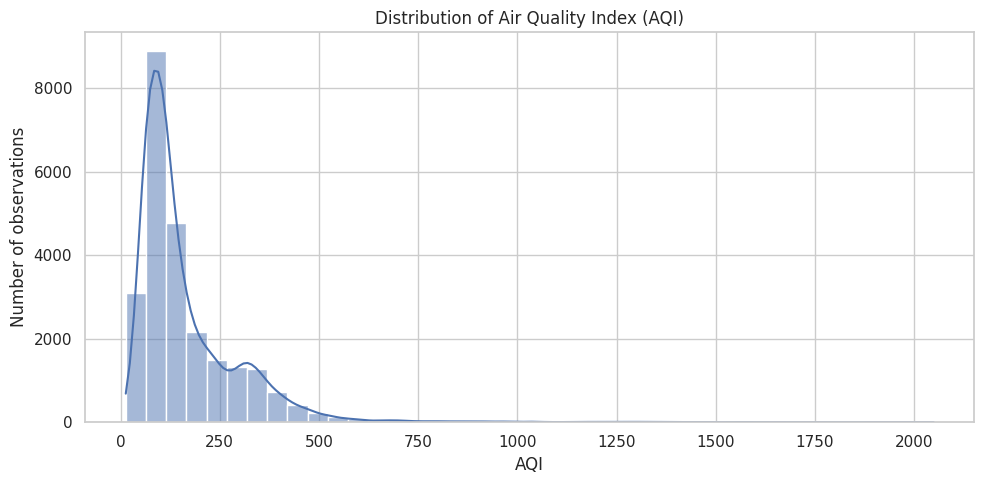

In [8]:
if "AQI" not in df.columns:
    raise ValueError("The dataset must contain an AQI column.")

aqi_data = df.dropna(subset=["AQI"])

plt.figure(figsize=(10, 5))
sns.histplot(aqi_data["AQI"], bins=40, kde=True)
plt.title("Distribution of Air Quality Index (AQI)")
plt.xlabel("AQI")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.savefig("aqi_distribution.png", dpi=150)
plt.show()

Top 10 cities by mean recorded AQI:


,Mean AQI
City,
Ahmedabad,452.122939
Delhi,259.487744
Patna,240.782042
Gurugram,225.123882
Lucknow,217.973059
Talcher,172.886819
Jorapokhar,159.251621
Brajrajnagar,150.280505
Kolkata,140.566313


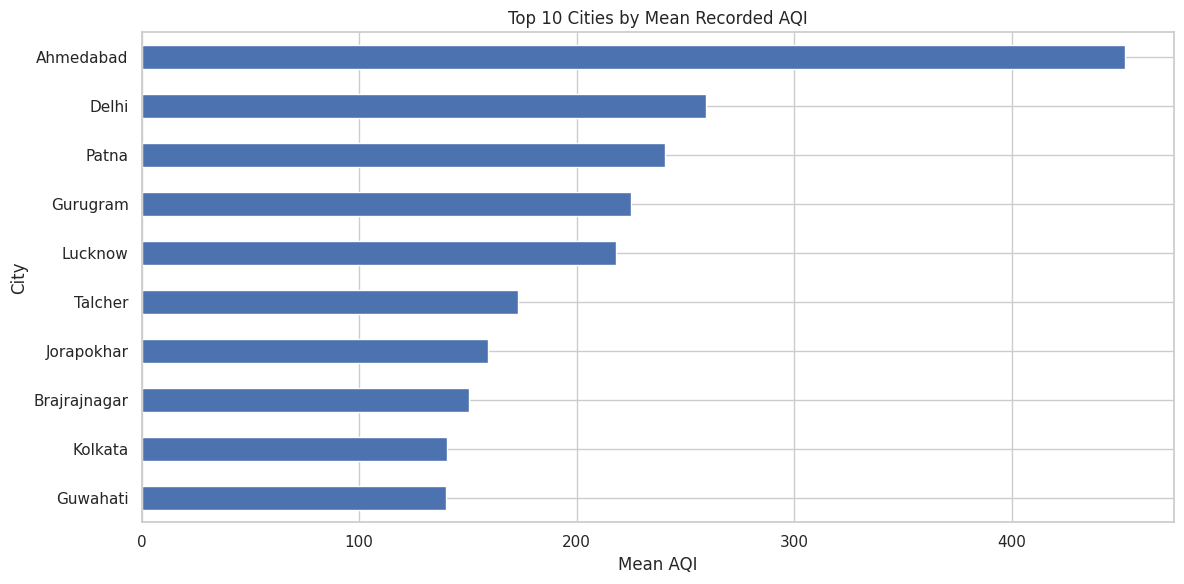

In [9]:
if "City" in df.columns:
    city_aqi = (
        df.dropna(subset=["AQI"])
          .groupby("City")["AQI"]
          .mean()
          .sort_values(ascending=False)
    )

    print("Top 10 cities by mean recorded AQI:")
    display(city_aqi.head(10).rename("Mean AQI").to_frame())

    plt.figure(figsize=(12, 6))
    city_aqi.head(10).sort_values().plot(kind="barh")
    plt.title("Top 10 Cities by Mean Recorded AQI")
    plt.xlabel("Mean AQI")
    plt.ylabel("City")
    plt.tight_layout()
    plt.savefig("eda.png", dpi=150)
    plt.show()

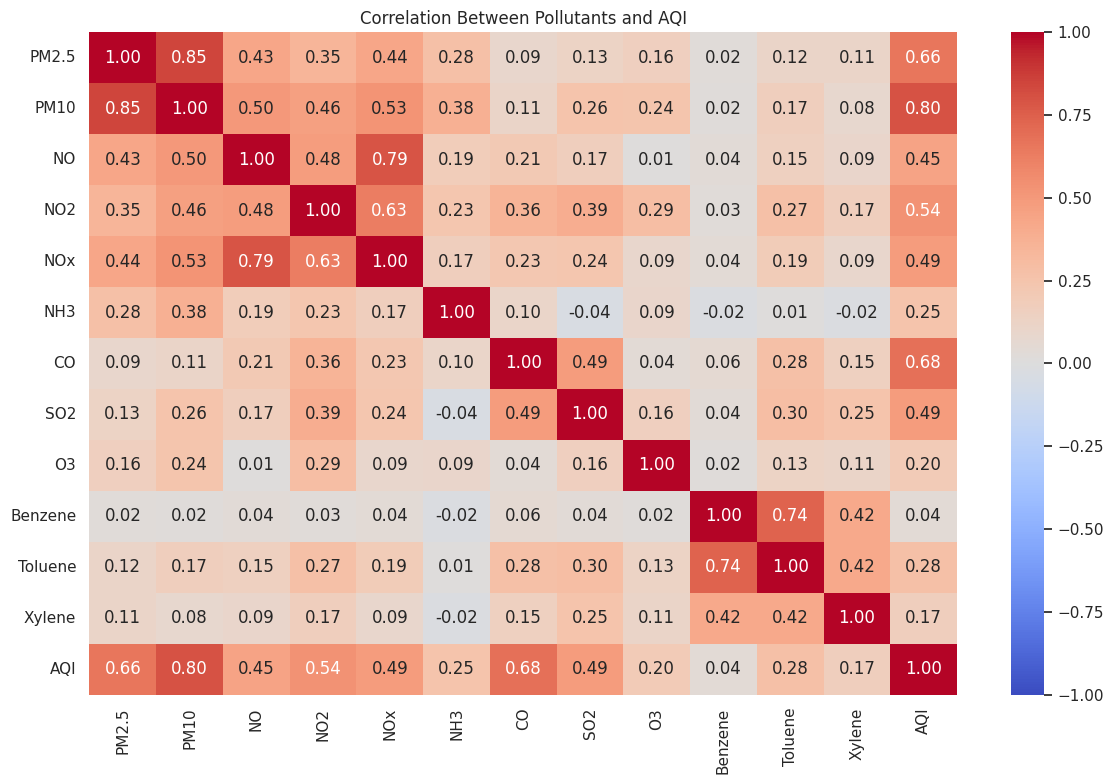

Pollutants most positively correlated with AQI:


,Correlation with AQI
PM10,0.803313
CO,0.683346
PM2.5,0.659181
NO2,0.537071
SO2,0.490586
NOx,0.486450
NO,0.452191
Toluene,0.279992
NH3,0.252019
O3,0.198991


In [10]:
correlation_columns = pollutant_columns.copy()

if "AQI" in df.columns:
    correlation_columns.append("AQI")

corr = df[correlation_columns].corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Between Pollutants and AQI")
plt.tight_layout()
plt.savefig("correlation.png", dpi=150)
plt.show()

if "AQI" in corr.columns:
    print("Pollutants most positively correlated with AQI:")
    display(
        corr["AQI"]
        .drop("AQI")
        .sort_values(ascending=False)
        .to_frame("Correlation with AQI")
    )

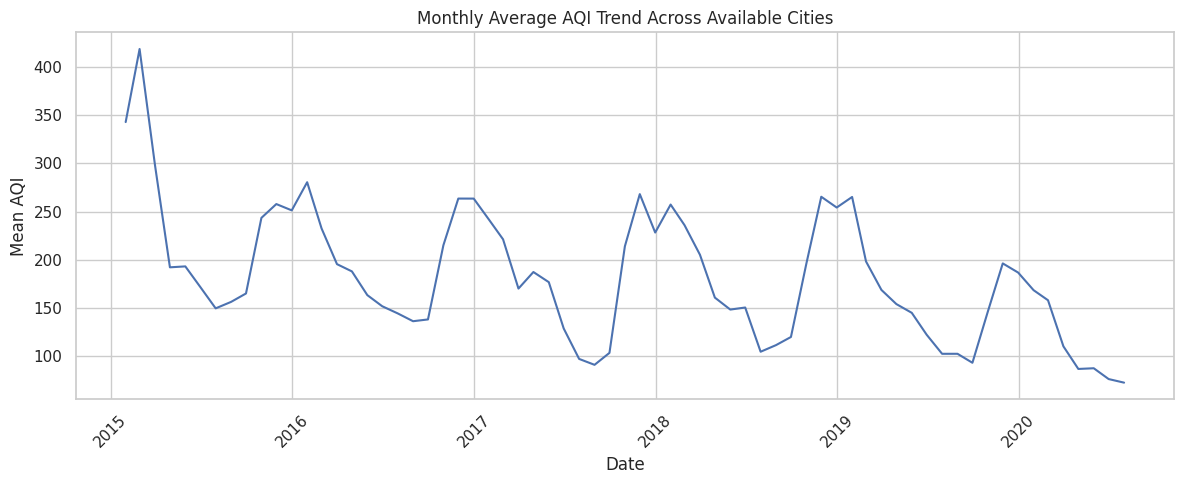

In [11]:
if "Date" in df.columns:
    monthly_aqi = (
        df.dropna(subset=["AQI", "Date"])
          .set_index("Date")["AQI"]
          .resample("ME")
          .mean()
          .dropna()
    )

    plt.figure(figsize=(12, 5))
    plt.plot(monthly_aqi.index, monthly_aqi.values)
    plt.title("Monthly Average AQI Trend Across Available Cities")
    plt.xlabel("Date")
    plt.ylabel("Mean AQI")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig("aqi_trend.png", dpi=150)
    plt.show()

In [12]:
if len(pollutant_columns) == 0:
    raise ValueError("No supported pollutant columns were found.")

# Regression: predict numeric AQI
reg_data = df.dropna(subset=["AQI"]).copy()

X = reg_data[pollutant_columns]
y = reg_data["AQI"]

# Hold out 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Number of features:", len(pollutant_columns))
print("Features:", pollutant_columns)

Training rows: 19880
Testing rows: 4970
Number of features: 12
Features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']


In [13]:
reg_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

reg_model.fit(X_train, y_train)

y_pred = reg_model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print("REGRESSION RESULTS")
print("------------------")
print(f"R2 Score: {r2:.4f}")
print(f"RMSE:     {rmse:.4f}")
print(f"MAE:      {mae:.4f}")

REGRESSION RESULTS
------------------
R2 Score: 0.9080
RMSE:     41.0381
MAE:      20.8359


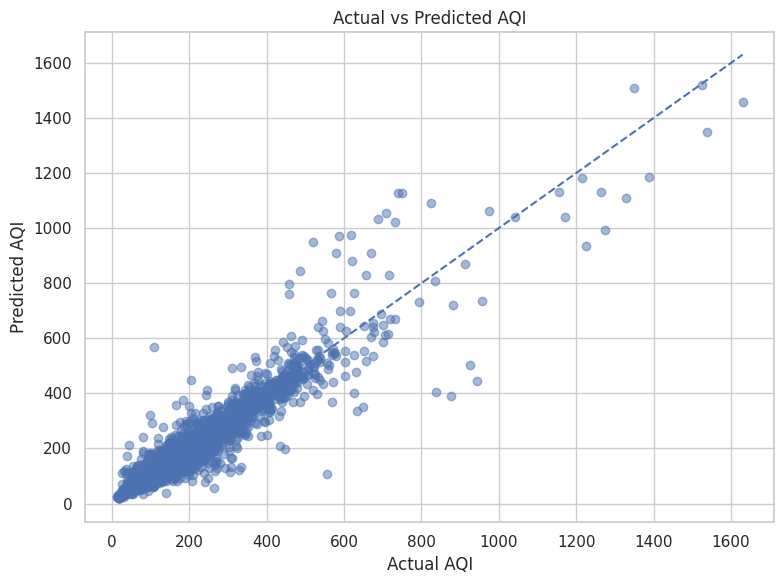

In [14]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Predicted AQI")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=150)
plt.show()

Feature importance ranking:


,Importance
PM2.5,0.490979
CO,0.367641
NO,0.037736
PM10,0.036536
O3,0.014287
NOx,0.012065
SO2,0.009921
NO2,0.008251
Toluene,0.007615
Xylene,0.006221


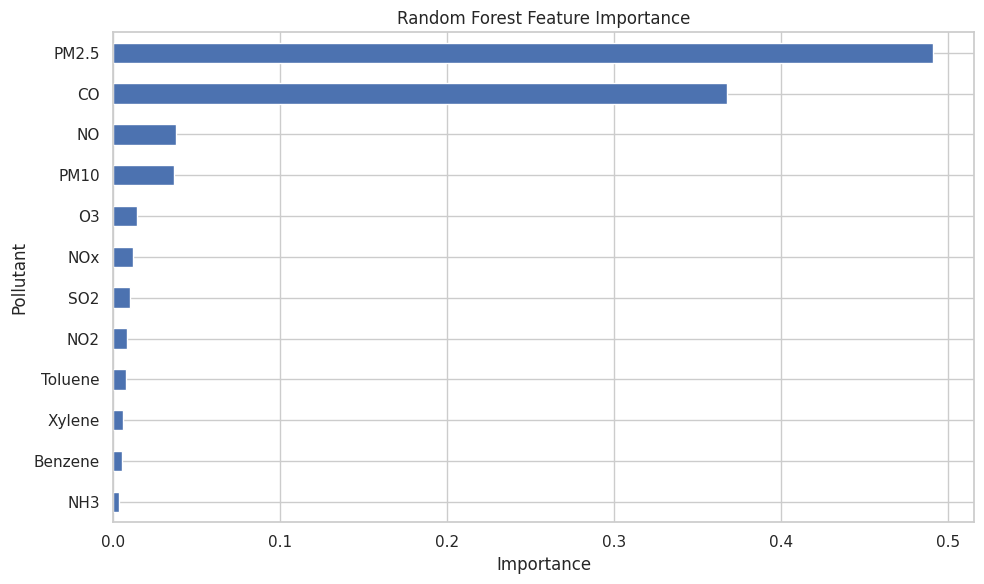

In [15]:
rf = reg_model.named_steps["model"]

importance = pd.Series(
    rf.feature_importances_,
    index=pollutant_columns
).sort_values(ascending=False)

print("Feature importance ranking:")
display(importance.to_frame("Importance"))

plt.figure(figsize=(10, 6))
importance.sort_values().plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Pollutant")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

In [16]:
if "AQI_Bucket" not in df.columns:
    print("AQI_Bucket is unavailable; skipping classification.")
else:
    cls_data = df.dropna(subset=["AQI_Bucket"]).copy()

    X_cls = cls_data[pollutant_columns]
    y_cls = cls_data["AQI_Bucket"].astype(str)

    # Remove categories with fewer than 2 examples
    counts = y_cls.value_counts()
    keep = y_cls.isin(counts[counts >= 2].index)

    X_cls = X_cls.loc[keep]
    y_cls = y_cls.loc[keep]

    if y_cls.nunique() < 2:
        print("Not enough categories to train a classifier.")
    else:
        Xc_train, Xc_test, yc_train, yc_test = train_test_split(
            X_cls,
            y_cls,
            test_size=0.20,
            random_state=42,
            stratify=y_cls
        )

        cls_model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                class_weight="balanced",
                n_jobs=-1
            ))
        ])

        cls_model.fit(Xc_train, yc_train)
        yc_pred = cls_model.predict(Xc_test)

        accuracy = accuracy_score(yc_test, yc_pred)

        print("CLASSIFICATION RESULTS")
        print("----------------------")
        print(f"Accuracy: {accuracy:.4f}")
        print(f"Accuracy percentage: {accuracy * 100:.2f}%")

        print("\nClassification report:")
        print(classification_report(
            yc_test,
            yc_pred,
            zero_division=0
        ))

CLASSIFICATION RESULTS
----------------------
Accuracy: 0.8127
Accuracy percentage: 81.27%

Classification report:
              precision    recall  f1-score   support

        Good       0.78      0.66      0.72       268
    Moderate       0.81      0.85      0.83      1766
        Poor       0.73      0.65      0.69       556
Satisfactory       0.84      0.85      0.85      1645
      Severe       0.87      0.82      0.85       268
   Very Poor       0.79      0.79      0.79       467

    accuracy                           0.81      4970
   macro avg       0.80      0.77      0.79      4970
weighted avg       0.81      0.81      0.81      4970



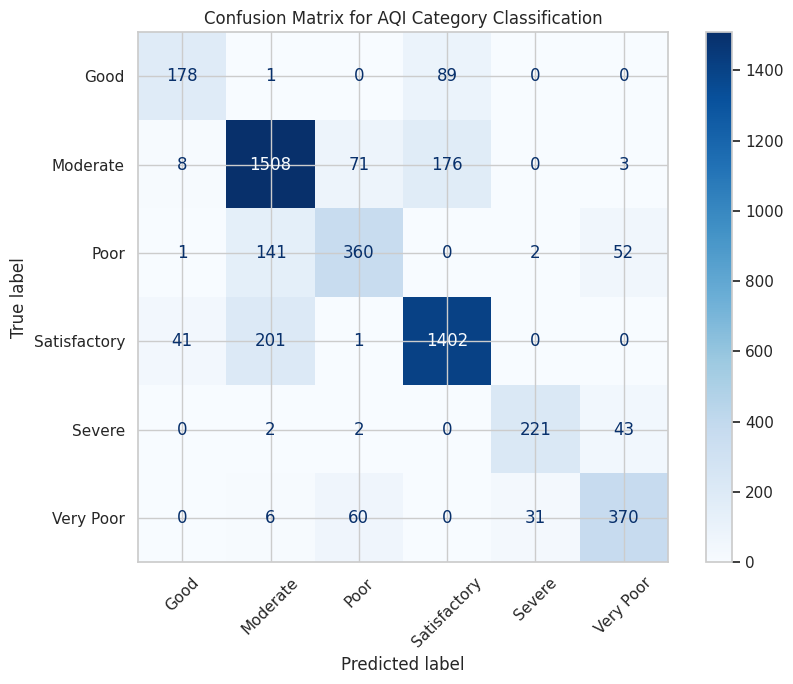

In [17]:
if "cls_model" in globals() and "yc_test" in globals():
    fig, ax = plt.subplots(figsize=(9, 7))

    ConfusionMatrixDisplay.from_predictions(
        yc_test,
        yc_pred,
        labels=cls_model.classes_,
        xticks_rotation=45,
        cmap="Blues",
        ax=ax
    )

    plt.title("Confusion Matrix for AQI Category Classification")
    plt.tight_layout()
    plt.savefig("confusion_matrix.png", dpi=150)
    plt.show()
else:
    print("Run Cell 14 successfully before generating this chart.")

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, estimator in models.items():
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", estimator)
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "R2": r2_score(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("Model comparison (lower RMSE is better):")
display(results_df.round(4))

best_model_name = results_df.iloc[0]["Model"]
print("Best model based on test RMSE:", best_model_name)

Model comparison (lower RMSE is better):


,Model,R2,RMSE,MAE
0,Random Forest,0.9080,41.0381,20.8359
1,Decision Tree,0.8246,56.6724,29.3193
2,Linear Regression,0.8071,59.4397,31.1698


Best model based on test RMSE: Random Forest


In [19]:
print("=" * 50)
print("INDIA AIR QUALITY ANALYSIS AND PREDICTION")
print("=" * 50)

print("\n1. DATASET")
print("Rows:", len(df))
print("Columns:", len(df.columns))

if "City" in df.columns:
    print("Number of cities:", df["City"].nunique())

print("\n2. TOP 5 CITIES BY MEAN AQI")
if "City" in df.columns:
    display(
        df.groupby("City")["AQI"]
          .mean()
          .sort_values(ascending=False)
          .head(5)
          .to_frame("Mean AQI")
          .round(2)
    )

print("\n3. REGRESSION METRICS")
print("R2:", round(r2, 4))
print("RMSE:", round(rmse, 4))
print("MAE:", round(mae, 4))

print("\n4. TOP 5 IMPORTANT FEATURES")
display(importance.head(5).to_frame("Importance").round(4))

print("\n5. BEST MODEL")
print(best_model_name)

if "accuracy" in globals():
    print("\n6. CLASSIFICATION ACCURACY")
    print(f"{accuracy * 100:.2f}%")

print("\nProject analysis completed.")

INDIA AIR QUALITY ANALYSIS AND PREDICTION

1. DATASET
Rows: 29531
Columns: 16
Number of cities: 26

2. TOP 5 CITIES BY MEAN AQI


,Mean AQI
City,
Ahmedabad,452.12
Delhi,259.49
Patna,240.78
Gurugram,225.12
Lucknow,217.97



3. REGRESSION METRICS
R2: 0.908
RMSE: 41.0381
MAE: 20.8359

4. TOP 5 IMPORTANT FEATURES


,Importance
PM2.5,0.4910
CO,0.3676
NO,0.0377
PM10,0.0365
O3,0.0143



5. BEST MODEL
Random Forest

6. CLASSIFICATION ACCURACY
81.27%

Project analysis completed.


In [20]:
import os
import zipfile

chart_names = [
    "eda.png",
    "correlation.png",
    "actual_vs_predicted.png",
    "feature_importance.png",
    "confusion_matrix.png",
    "aqi_distribution.png",
    "aqi_trend.png"
]

with zipfile.ZipFile(
    "aqi_project_charts.zip", "w"
) as archive:
    for chart in chart_names:
        if os.path.exists(chart):
            archive.write(chart)

print("Charts included in the ZIP:")
with zipfile.ZipFile("aqi_project_charts.zip") as archive:
    print("\n".join(archive.namelist()))

files.download("aqi_project_charts.zip")

Charts included in the ZIP:
eda.png
correlation.png
actual_vs_predicted.png
feature_importance.png
confusion_matrix.png
aqi_distribution.png
aqi_trend.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>